# v1 - SPY trend + volatility targeting

Robert Miller

I started this project with an older script that used leverage, VWAP, MACD and a grid search over the whole data set. When I looked at it more closely, it ignored dividends, assumed borrowing was free, and picked its settings using the same years it was scored on. So for v1 I started over with something simpler.

For v1, the goal is to keep most of the market's return (the beta) while sitting out the worst stretches, so the drawdowns are smaller. Beating the S&P 500 outright would be a bonus. It only holds SPY and T-bills, never more than 100% SPY, and it's checked once a month in a regular taxable account.

### Rules

On the last trading day of each month, I first check the trend. If SPY is above its N-month average, the trend is up and the strategy holds SPY. If it's below, it moves to T-bills, or only partly to T-bills if the "off weight" setting is above zero. In addition, the SPY weight is scaled by volatility, so it equals a target volatility divided by SPY's recent realized volatility, capped at 100%. This is the Moreira and Muir (2017) idea of taking less risk when the market is jumpy. Whatever isn't in SPY earns the 3-month T-bill rate, and if a trade would change the position by less than 5% of the account, it gets skipped.

### Fees and taxes

$10,000 start, $0 commission, and 5 bps of spread/slippage. SPY's 0.0945% fee is already in the price. Cash is SGOV, so the T-bill rate minus 0.09%. Federal tax only: 22% on short-term gains and interest, 15% on long-term gains and dividends.

Trades go in at the next day's close after the signal, since you can't trade at a close you haven't seen yet (my first draft made this mistake).

Data is SPY from Yahoo Finance (Adj Close, so dividends are in) and the 3-month T-bill rate (DTB3) from FRED. Run `python get_data.py` first.

### What this notebook reproduces

This is the full analysis behind v1 in the README. Section 2 here is the v1 row of README Table 2, Section 3 gives the v1 risk numbers in README Section 5.1, and Section 5 gives the v1 row of README Table 3. It reads `SPY.csv` and `dtb3.csv` from the `data/` folder, so run `python get_data.py` from the main folder first, and then run every cell from top to bottom. The last cell prints the package versions and data files it was run with.

In [1]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from strategy import (load_data, run_backtest, run_buy_and_hold, run_static_mix,
                      get_stats, block_bootstrap, chosen_settings, start_value)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

data = load_data()

print("First date:", data.index[0].date())
print("Last date:", data.index[-1].date())
print("Trading days:", len(data))

First date: 1993-01-29
Last date: 2026-10-29
Trading days: 8496


## 1. Train / test split

Settings get picked on the training years only, and I don't look at the test years until they're locked in. Training includes the dot com crash and 2008, and testing includes 2020 and the 2022 bear market.

In [2]:
train_end = "2009-12-31"
test_start = "2010-01-01"

train = data.loc[:train_end]
test_data = data.loc[test_start:]

print("Training:", train.index[0].date(), "to", train.index[-1].date())
print("Testing:", test_data.index[0].date(), "to", test_data.index[-1].date())

Training: 1993-01-29 to 2009-12-31
Testing: 2010-01-04 to 2026-10-29


## 2. Picking settings

I rank every combination by Sharpe ratio (return over T-bills per unit of risk) instead of final growth. Ranking by growth would just pick whatever holds the most SPY, which would defeat the point.

The first year is used to warm up the averages, so every combination gets scored over the same dates.

This grid is the v1 row of Table 2 in the README.

In [3]:
sma_months_list = [6, 8, 10, 12]
vol_window_list = [21, 63]
target_vol_list = [0.10, 0.125, 0.15, 0.20]
off_weight_list = [0.0, 0.25, 0.5]

score_start = "1995-01-01"

results = []

for sma_months in sma_months_list:
    for vol_window in vol_window_list:
        for target_vol in target_vol_list:
            for off_weight in off_weight_list:

                bt = run_backtest(train, sma_months, vol_window, target_vol, off_weight,
                                  start=score_start)

                stats = get_stats(bt["strategy_return"], bt["tbill_return"], bt["spy_return"])

                stats["sma_months"] = sma_months
                stats["vol_window"] = vol_window
                stats["target_vol"] = target_vol
                stats["off_weight"] = off_weight
                stats["avg_exposure"] = bt["exposure"].mean()

                results.append(stats)

train_results = pd.DataFrame(results).sort_values("sharpe", ascending=False)

columns = ["sma_months", "vol_window", "target_vol", "off_weight", "sharpe",
           "cagr", "volatility", "max_drawdown", "avg_exposure"]

print("Combinations tested:", len(train_results))
train_results[columns].head(10)

Combinations tested: 96


,sma_months,vol_window,target_vol,off_weight,sharpe,cagr,volatility,max_drawdown,avg_exposure
81,12,21,0.200,0.000,0.755,0.128,0.125,-0.184,0.699
72,12,21,0.100,0.000,0.754,0.102,0.089,-0.110,0.543
87,12,63,0.125,0.000,0.752,0.111,0.102,-0.146,0.608
57,10,21,0.200,0.000,0.749,0.126,0.124,-0.184,0.694
75,12,21,0.125,0.000,0.748,0.111,0.103,-0.138,0.610
84,12,63,0.100,0.000,0.743,0.100,0.088,-0.116,0.533
93,12,63,0.200,0.000,0.742,0.126,0.124,-0.190,0.691
48,10,21,0.100,0.000,0.741,0.100,0.088,-0.110,0.539
78,12,21,0.150,0.000,0.737,0.118,0.114,-0.166,0.651
63,10,63,0.125,0.000,0.736,0.108,0.100,-0.146,0.599


In [4]:
best = train_results.iloc[0]

best_settings = {
    "sma_months": int(best["sma_months"]),
    "vol_window": int(best["vol_window"]),
    "target_vol": float(best["target_vol"]),
    "off_weight": float(best["off_weight"]),
}

print("Best settings on training data:", best_settings)
print("Settings saved in strategy.py:", chosen_settings)

if best_settings != chosen_settings:
    print("These do not match. Update chosen_settings in strategy.py so monthly_signal.py uses them.")

# buy and hold over the same training dates for reference
train_spy = run_buy_and_hold(train, start=score_start)
spy_train_stats = get_stats(train_spy["strategy_return"], train_spy["tbill_return"], train_spy["spy_return"])
print()
print("Buy and hold training Sharpe:", round(spy_train_stats["sharpe"], 2))
print("Strategy training Sharpe:", round(best["sharpe"], 2))

Best settings on training data: {'sma_months': 12, 'vol_window': 21, 'target_vol': 0.2, 'off_weight': 0.0}
Settings saved in strategy.py: {'sma_months': 12, 'vol_window': 21, 'target_vol': 0.2, 'off_weight': 0.0}

Buy and hold training Sharpe: 0.31
Strategy training Sharpe: 0.75


## 3. Testing on 2010 to now

The locked-in settings vs:
- buy and hold SPY
- a static mix that holds the same average amount of SPY as the strategy. I think this is the fairest comparison, because if the strategy can't beat a simple fixed mix with the same exposure, the timing isn't adding anything.
- trend only and vol target only, to see which half is doing the work

Before taxes here, after-tax results are further down.

The before-tax risk numbers in README Section 5.1 (drawdown, beta and Sharpe ratio) come from this section.

In [5]:
s = best_settings

strategy_test = run_backtest(data, s["sma_months"], s["vol_window"], s["target_vol"], s["off_weight"],
                             start=test_start)

# trend only (huge target vol = weight always 1)
trend_test = run_backtest(data, s["sma_months"], s["vol_window"], 10.0, 0.0, start=test_start)

# vol target only (off_weight = 1)
vol_test = run_backtest(data, s["sma_months"], s["vol_window"], s["target_vol"], 1.0, start=test_start)

avg_exposure = strategy_test["exposure"].mean()
static_test = run_static_mix(data, avg_exposure, start=test_start)

hold_test = run_buy_and_hold(data, start=test_start)

spy_returns = strategy_test["spy_return"]
cash_returns = strategy_test["tbill_return"]

table = pd.DataFrame({
    "Strategy": get_stats(strategy_test["strategy_return"], cash_returns, spy_returns),
    "Buy and hold": get_stats(hold_test["strategy_return"], cash_returns, spy_returns),
    "Static mix": get_stats(static_test["strategy_return"], cash_returns, spy_returns),
    "Trend only": get_stats(trend_test["strategy_return"], cash_returns, spy_returns),
    "Vol target only": get_stats(vol_test["strategy_return"], cash_returns, spy_returns),
})

print("Average SPY exposure:", round(avg_exposure, 2))
years = len(strategy_test) / 252
turnover = (strategy_test["traded"] / strategy_test["value"]).sum() / years

print("Trades:", int((strategy_test["traded"] > 0).sum()), "in", round(years, 1), "years")
print("Average turnover per year:", str(round(turnover * 100)) + "% of the account")
print("Total trading costs: $" + format(round(strategy_test["cost"].sum(), 2), ","))
table

Average SPY exposure: 0.84
Trades: 35 in 16.8 years
Average turnover per year: 158% of the account
Total trading costs: $229.35


,Strategy,Buy and hold,Static mix,Trend only,Vol target only
growth_of_1,4.499,9.114,6.995,4.487,7.497
cagr,0.094,0.141,0.123,0.093,0.127
volatility,0.127,0.170,0.146,0.130,0.154
sharpe,0.651,0.772,0.767,0.638,0.762
sortino,0.896,1.086,1.075,0.877,1.062
max_drawdown,-0.209,-0.337,-0.297,-0.210,-0.293
calmar,0.448,0.417,0.413,0.446,0.435
beta,0.571,0.999,0.856,0.586,0.886
daily_var_95,-0.013,-0.016,-0.014,-0.014,-0.015


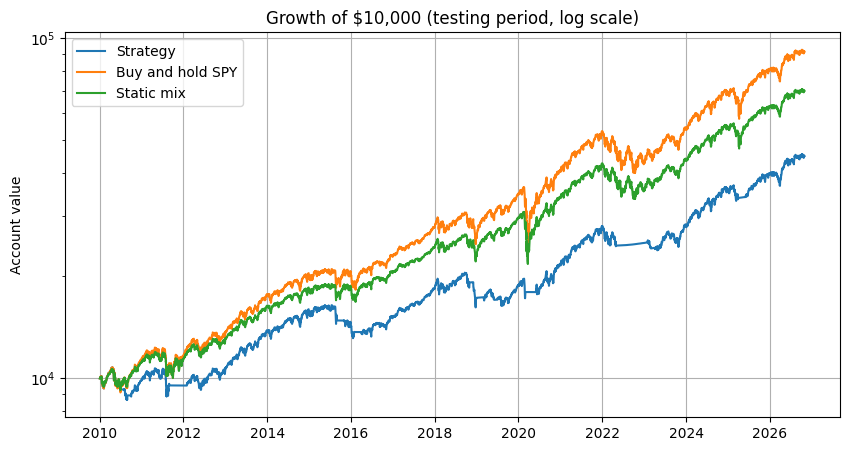

Strategy final value: $44,988
Buy and hold final value: $91,144
Static mix final value: $69,950


In [6]:
growth = pd.DataFrame({
    "Strategy": strategy_test["value"],
    "Buy and hold SPY": hold_test["value"],
    "Static mix": static_test["value"],
})

plt.figure(figsize=(10,5))
for name in growth.columns:
    plt.plot(growth.index, growth[name], label=name)
plt.yscale("log")
plt.title("Growth of $10,000 (testing period, log scale)")
plt.ylabel("Account value")
plt.legend()
plt.grid(True)
plt.show()

print("Strategy final value: $" + format(round(growth["Strategy"].iloc[-1]), ","))
print("Buy and hold final value: $" + format(round(growth["Buy and hold SPY"].iloc[-1]), ","))
print("Static mix final value: $" + format(round(growth["Static mix"].iloc[-1]), ","))

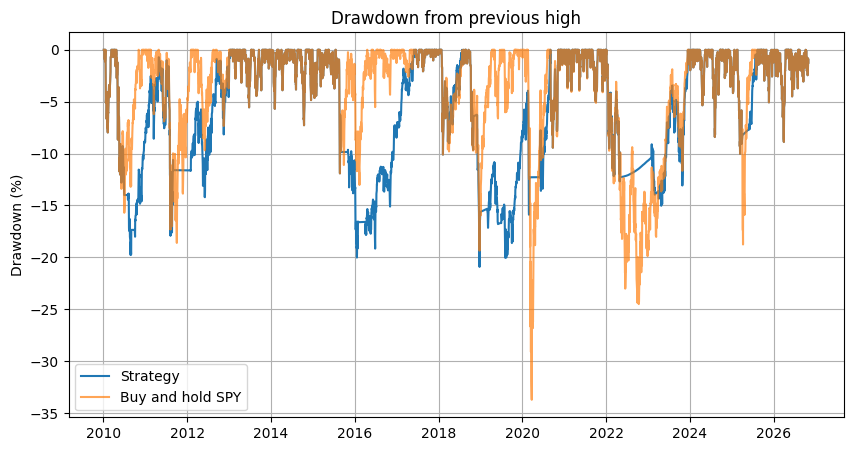

In [7]:
def drawdown_series(returns):
    growth = (1 + returns).cumprod()
    return growth / growth.cummax() - 1

plt.figure(figsize=(10,5))
plt.plot(strategy_test.index, drawdown_series(strategy_test["strategy_return"]) * 100, label="Strategy")
plt.plot(hold_test.index, drawdown_series(hold_test["strategy_return"]) * 100, label="Buy and hold SPY", alpha=0.7)
plt.title("Drawdown from previous high")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(True)
plt.show()

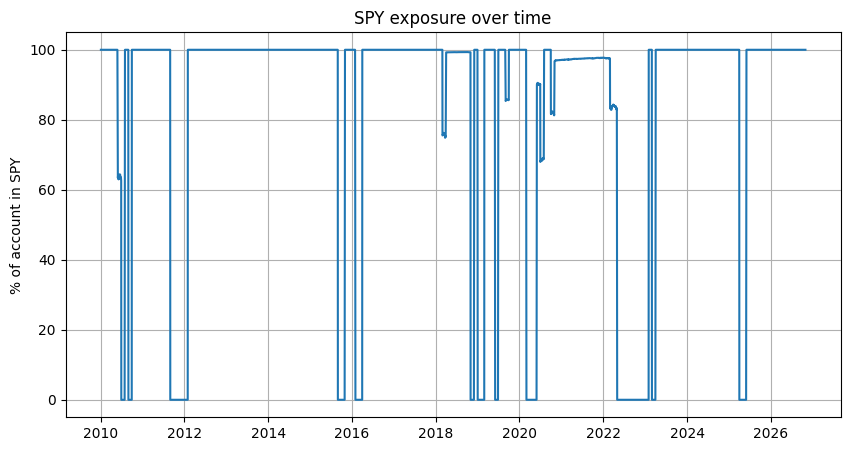

Time fully in SPY: 69.7%
Time fully in T-bills: 14.9%


In [8]:
plt.figure(figsize=(10,5))
plt.plot(strategy_test.index, strategy_test["exposure"] * 100)
plt.title("SPY exposure over time")
plt.ylabel("% of account in SPY")
plt.ylim(-5, 105)
plt.grid(True)
plt.show()

print("Time fully in SPY:", str(round((strategy_test["exposure"] >= 0.999).mean() * 100, 1)) + "%")
print("Time fully in T-bills:", str(round((strategy_test["exposure"] <= 0.001).mean() * 100, 1)) + "%")

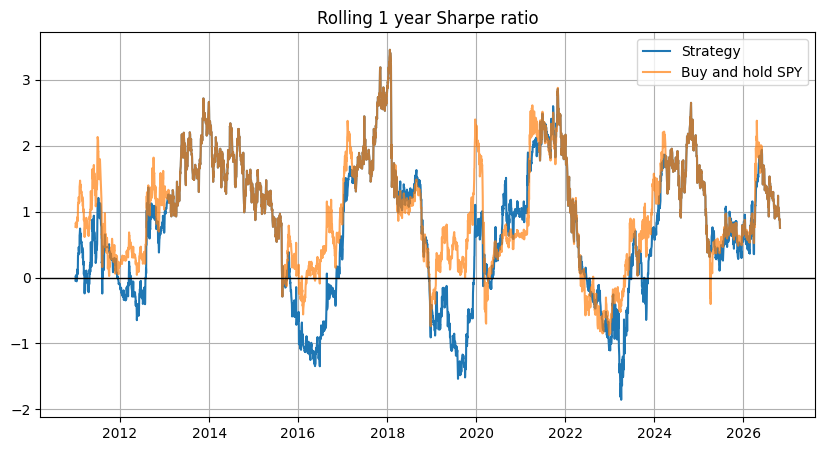

In [9]:
# rolling 1 year Sharpe ratio
window = 252

strategy_excess = strategy_test["strategy_return"] - cash_returns
spy_excess = hold_test["strategy_return"] - cash_returns

rolling_strategy = strategy_excess.rolling(window).mean() / strategy_excess.rolling(window).std() * math.sqrt(252)
rolling_spy = spy_excess.rolling(window).mean() / spy_excess.rolling(window).std() * math.sqrt(252)

plt.figure(figsize=(10,5))
plt.plot(rolling_strategy.index, rolling_strategy, label="Strategy")
plt.plot(rolling_spy.index, rolling_spy, label="Buy and hold SPY", alpha=0.7)
plt.axhline(0, color="black", linewidth=1)
plt.title("Rolling 1 year Sharpe ratio")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# calendar year returns
yearly = pd.DataFrame({
    "Strategy": (1 + strategy_test["strategy_return"]).groupby(strategy_test.index.year).prod() - 1,
    "Buy and hold": (1 + hold_test["strategy_return"]).groupby(hold_test.index.year).prod() - 1,
    "Avg exposure": strategy_test["exposure"].groupby(strategy_test.index.year).mean(),
})
yearly["Difference"] = yearly["Strategy"] - yearly["Buy and hold"]

# rounded so the fully invested years count as ties, not wins
print("Years the strategy beat buy and hold:", int((yearly["Difference"].round(6) > 0).sum()), "out of", len(yearly))
yearly

Years the strategy beat buy and hold: 1 out of 17


,Strategy,Buy and hold,Avg exposure,Difference
date,,,,
2010,-0.017,0.131,0.802,-0.148
2011,-0.030,0.019,0.667,-0.049
2012,0.098,0.160,0.920,-0.062
2013,0.323,0.323,1.000,0.000
2014,0.135,0.135,1.000,0.000
2015,-0.083,0.012,0.829,-0.095
2016,0.042,0.120,0.833,-0.078
2017,0.217,0.217,1.000,-0.000
2018,-0.057,-0.046,0.892,-0.011


## 4. Was the pick just lucky?

If only the one best setting does well on the test years, it's probably overfit. So this runs every combination on the test years, not just the winner.

Settings with a higher Sharpe than buy and hold: 6 out of 96
Settings with a smaller max drawdown than buy and hold: 96 out of 96
Median Sharpe across all settings: 0.69


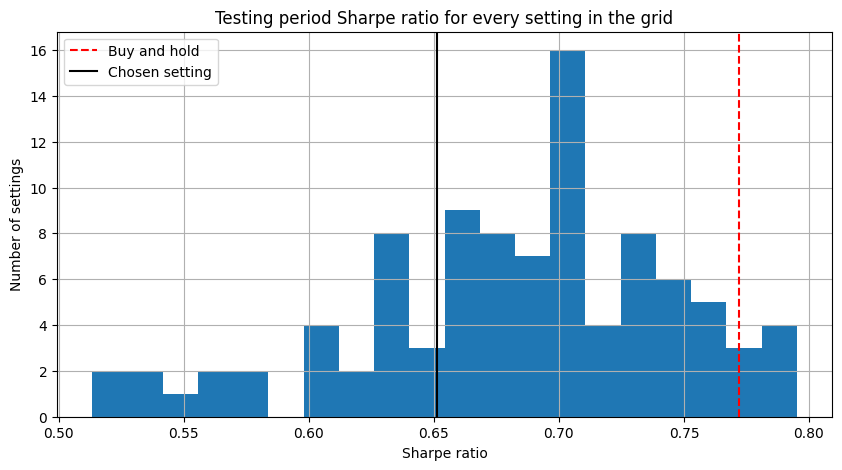

In [11]:
test_results = []

for sma_months in sma_months_list:
    for vol_window in vol_window_list:
        for target_vol in target_vol_list:
            for off_weight in off_weight_list:

                bt = run_backtest(data, sma_months, vol_window, target_vol, off_weight, start=test_start)
                stats = get_stats(bt["strategy_return"], bt["tbill_return"], bt["spy_return"])
                test_results.append(stats)

test_results = pd.DataFrame(test_results)
spy_test_sharpe = table.loc["sharpe", "Buy and hold"]
spy_test_drawdown = table.loc["max_drawdown", "Buy and hold"]

print("Settings with a higher Sharpe than buy and hold:",
      int((test_results["sharpe"] > spy_test_sharpe).sum()), "out of", len(test_results))
print("Settings with a smaller max drawdown than buy and hold:",
      int((test_results["max_drawdown"] > spy_test_drawdown).sum()), "out of", len(test_results))
print("Median Sharpe across all settings:", round(test_results["sharpe"].median(), 2))

plt.figure(figsize=(10,5))
plt.hist(test_results["sharpe"], bins=20)
plt.axvline(spy_test_sharpe, color="red", linestyle="--", label="Buy and hold")
plt.axvline(table.loc["sharpe", "Strategy"], color="black", label="Chosen setting")
plt.title("Testing period Sharpe ratio for every setting in the grid")
plt.xlabel("Sharpe ratio")
plt.ylabel("Number of settings")
plt.legend()
plt.grid(True)
plt.show()

## 5. After taxes

This is the most important section for a taxable account. Buy and hold only pays tax on dividends each year and lets its gains build up untaxed. On the other hand, the strategy sells when the trend breaks, so it realizes gains, and many of them are short-term (22% instead of 15%).

How taxes work in the backtest:
- every purchase is its own tax lot, and sales use the oldest shares first (FIFO, the default at most brokers)
- dividends and interest are taxed every year
- losses offset gains and carry forward. I don't credit the $3,000 deduction against other income, since that saving happens outside the account
- the wash sale rule is applied, so a loss on SPY bought back within 30 days gets pushed into the new shares' cost
- the tax bill comes out of the account each December

"Still invested" is the account value today. "If sold today" also pays tax on the gains that haven't been sold yet, which is the fairer comparison since buy and hold carries a large gain that hasn't been taxed yet.

The after-tax numbers here are the v1 row of Table 3 in the README.

In [12]:
strategy_tax = run_backtest(data, s["sma_months"], s["vol_window"], s["target_vol"], s["off_weight"],
                            start=test_start, taxes=True)
hold_tax = run_buy_and_hold(data, start=test_start, taxes=True)
static_tax = run_static_mix(data, avg_exposure, start=test_start, taxes=True)

years = len(strategy_tax) / 252
after_tax = {}

for name, bt, pre_tax in [("Strategy", strategy_tax, strategy_test),
                          ("Buy and hold", hold_tax, hold_test),
                          ("Static mix", static_tax, static_test)]:

    sold_value = bt.attrs["liquidation_value"]

    after_tax[name] = {
        "value_before_tax": pre_tax["value"].iloc[-1],
        "value_still_invested": bt["value"].iloc[-1],
        "value_if_sold_today": sold_value,
        "taxes_paid_so_far": bt.attrs["total_taxes"],
        "cagr_before_tax": (pre_tax["value"].iloc[-1] / start_value) ** (1 / years) - 1,
        "cagr_after_tax_sold": (sold_value / start_value) ** (1 / years) - 1,
        # pre-tax drawdown so it matches the other tables
        "max_drawdown": get_stats(pre_tax["strategy_return"], pre_tax["tbill_return"], pre_tax["spy_return"])["max_drawdown"],
    }

after_tax = pd.DataFrame(after_tax)

print("Starting value: $" + format(start_value, ","))
after_tax

Starting value: $10,000


,Strategy,Buy and hold,Static mix
value_before_tax,"44,987.771","91,144.331","69,949.541"
value_still_invested,"37,996.979","87,299.434","65,860.841"
value_if_sold_today,"36,603.609","76,769.447","58,975.341"
taxes_paid_so_far,"3,450.595","1,311.548","1,906.340"
cagr_before_tax,0.094,0.141,0.123
cagr_after_tax_sold,0.080,0.129,0.111
max_drawdown,-0.209,-0.337,-0.297


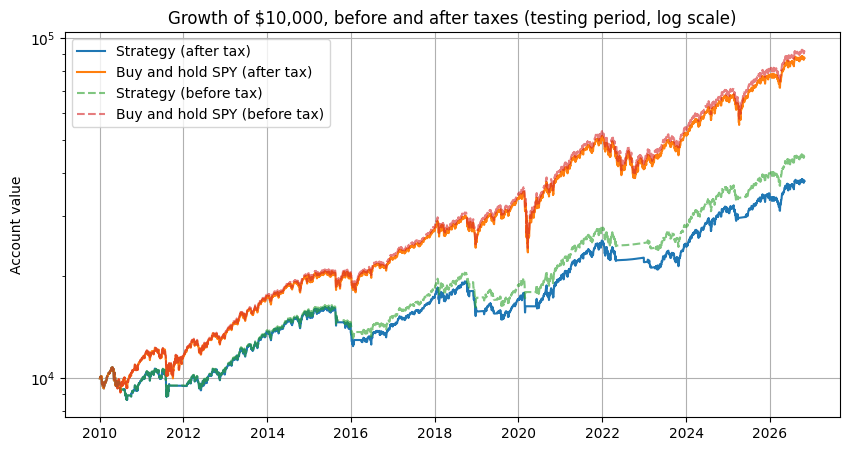

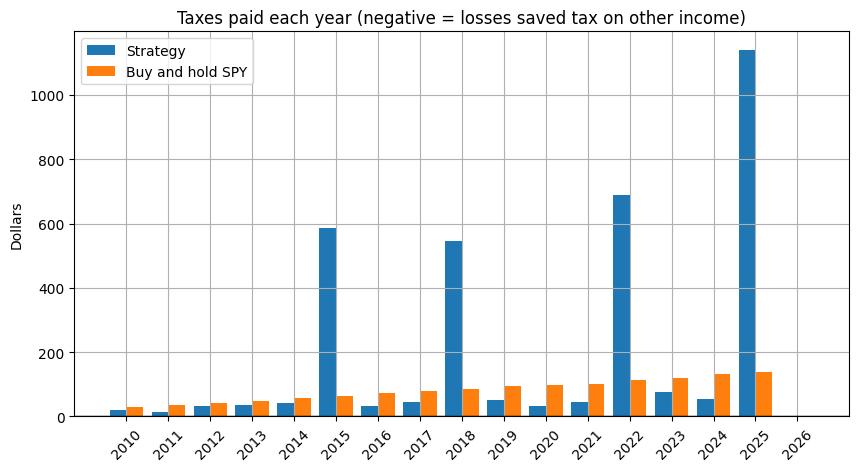

In [13]:
plt.figure(figsize=(10,5))
plt.plot(strategy_tax.index, strategy_tax["value"], label="Strategy (after tax)")
plt.plot(hold_tax.index, hold_tax["value"], label="Buy and hold SPY (after tax)")
plt.plot(strategy_test.index, strategy_test["value"], label="Strategy (before tax)", linestyle="--", alpha=0.6)
plt.plot(hold_test.index, hold_test["value"], label="Buy and hold SPY (before tax)", linestyle="--", alpha=0.6)
plt.yscale("log")
plt.title("Growth of $10,000, before and after taxes (testing period, log scale)")
plt.ylabel("Account value")
plt.legend()
plt.grid(True)
plt.show()

yearly_tax = pd.DataFrame({
    "Strategy": strategy_tax["taxes_paid"].groupby(strategy_tax.index.year).sum(),
    "Buy and hold": hold_tax["taxes_paid"].groupby(hold_tax.index.year).sum(),
})

plt.figure(figsize=(10,5))
x = np.arange(len(yearly_tax))
plt.bar(x - 0.2, yearly_tax["Strategy"], width=0.4, label="Strategy")
plt.bar(x + 0.2, yearly_tax["Buy and hold"], width=0.4, label="Buy and hold SPY")
plt.xticks(x, yearly_tax.index, rotation=45)
plt.axhline(0, color="black", linewidth=1)
plt.title("Taxes paid each year (negative = losses saved tax on other income)")
plt.ylabel("Dollars")
plt.legend()
plt.grid(True)
plt.show()

## 6. Monte Carlo (block bootstrap)

2,000 simulated 5-year periods built from random 21 day blocks of the test years (before tax), with the same blocks for the strategy and buy and hold so they see the same market. Blocks instead of single days because volatile days tend to come in clusters.

The main caveat is that this reshuffles the strategy's actual returns, which already include being in T-bills during the real crashes, so it can't show a world where the filter fails. It makes the strategy look more reliable than it is. v3 has a better version that re-runs the rules on new price paths.

In [14]:
mc = block_bootstrap(strategy_test["strategy_return"], hold_test["strategy_return"], cash_returns,
                     years=5, block_size=21, sims=2000)

print("Chance the strategy has a higher Sharpe:", str(round((mc["strategy_sharpe"] > mc["spy_sharpe"]).mean() * 100, 1)) + "%")
print("Chance the strategy has a smaller max drawdown:", str(round((mc["strategy_drawdown"] > mc["spy_drawdown"]).mean() * 100, 1)) + "%")
print("Chance the strategy has a higher CAGR:", str(round((mc["strategy_cagr"] > mc["spy_cagr"]).mean() * 100, 1)) + "%")
print()

summary = pd.DataFrame({
    "Strategy CAGR": mc["strategy_cagr"].quantile([0.05, 0.5, 0.95]),
    "SPY CAGR": mc["spy_cagr"].quantile([0.05, 0.5, 0.95]),
    "Strategy max DD": mc["strategy_drawdown"].quantile([0.05, 0.5, 0.95]),
    "SPY max DD": mc["spy_drawdown"].quantile([0.05, 0.5, 0.95]),
})
summary.index = ["5th percentile", "median", "95th percentile"]
summary

Chance the strategy has a higher Sharpe: 30.5%
Chance the strategy has a smaller max drawdown: 73.0%
Chance the strategy has a higher CAGR: 15.5%



,Strategy CAGR,SPY CAGR,Strategy max DD,SPY max DD
5th percentile,0.004,0.019,-0.315,-0.403
median,0.096,0.144,-0.177,-0.215
95th percentile,0.192,0.270,-0.108,-0.127


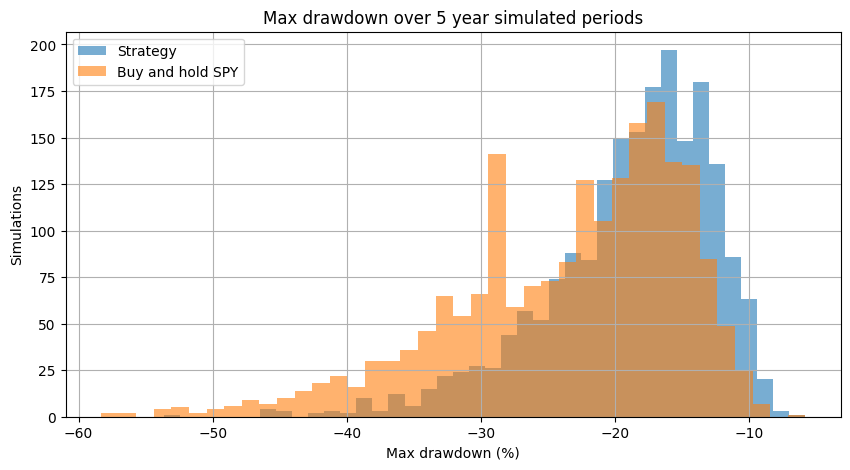

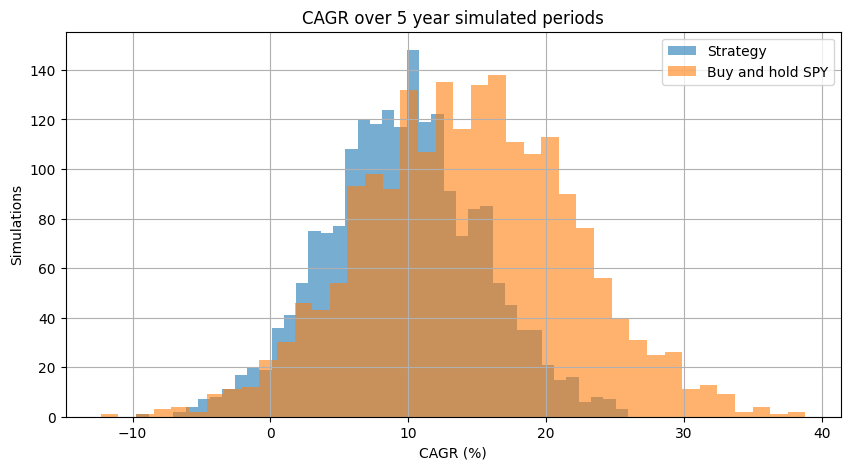

In [15]:
plt.figure(figsize=(10,5))
plt.hist(mc["strategy_drawdown"] * 100, bins=40, alpha=0.6, label="Strategy")
plt.hist(mc["spy_drawdown"] * 100, bins=40, alpha=0.6, label="Buy and hold SPY")
plt.title("Max drawdown over 5 year simulated periods")
plt.xlabel("Max drawdown (%)")
plt.ylabel("Simulations")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10,5))
plt.hist(mc["strategy_cagr"] * 100, bins=40, alpha=0.6, label="Strategy")
plt.hist(mc["spy_cagr"] * 100, bins=40, alpha=0.6, label="Buy and hold SPY")
plt.title("CAGR over 5 year simulated periods")
plt.xlabel("CAGR (%)")
plt.ylabel("Simulations")
plt.legend()
plt.grid(True)
plt.show()

## 7. Full history (just for context)

The chosen settings over the whole history, before tax. The training years are in-sample here, so this is only to see how it behaved in 2000-2002 and 2008.

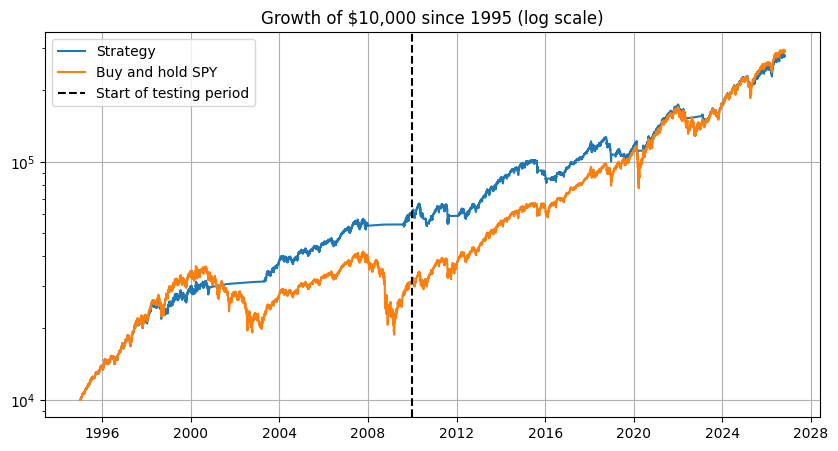

,Strategy,Buy and hold
growth_of_1,27.906,29.152
cagr,0.110,0.112
volatility,0.126,0.189
sharpe,0.704,0.530
sortino,0.984,0.751
max_drawdown,-0.209,-0.552
calmar,0.528,0.203
beta,0.460,1.000
daily_var_95,-0.013,-0.018


In [16]:
full = run_backtest(data, s["sma_months"], s["vol_window"], s["target_vol"], s["off_weight"],
                    start=score_start)
full_hold = run_buy_and_hold(data, start=score_start)

full_table = pd.DataFrame({
    "Strategy": get_stats(full["strategy_return"], full["tbill_return"], full["spy_return"]),
    "Buy and hold": get_stats(full_hold["strategy_return"], full_hold["tbill_return"], full_hold["spy_return"]),
})

plt.figure(figsize=(10,5))
plt.plot(full.index, full["value"], label="Strategy")
plt.plot(full_hold.index, full_hold["value"], label="Buy and hold SPY")
plt.axvline(pd.Timestamp(test_start), color="black", linestyle="--", label="Start of testing period")
plt.yscale("log")
plt.title("Growth of $10,000 since 1995 (log scale)")
plt.legend()
plt.grid(True)
plt.show()

full_table

## Findings

(Data through October 29, 2026, next-day trades, wash sale rule applied.)

On risk, it did what it was built to do. The max drawdown was about -21% vs -34% for buy and hold, volatility dropped from 17% to about 13%, and the beta was only 0.57.

On the other hand, it gave up too much return to get there. Buy and hold turned $10,000 into about $91,100 before taxes, while the strategy ended around $45,000. The Sharpe ratio was lower too (0.65 vs 0.77), so the smoother ride didn't make up for it. Even the static mix with the same average exposure did better (Sharpe 0.77, about $70,000), which means the timing itself hurt from 2010 on.

The trend filter is what cost the most. For example, it sold after the late 2018 drop and missed a big part of the 2019 rally (8% vs 31%), and it lagged in 2010, 2015-2016 and 2020 for the same reason. Vol targeting by itself came closest to buy and hold (Sharpe 0.76 vs 0.77). The filter's best year was 2022, when it was mostly in T-bills and lost about 10% vs 18% for SPY.

Taxes make the gap bigger. After selling everything and paying the tax, it ends around $36,600 vs $76,800 for buy and hold, since many of its gains are short-term.

Only 6 of the 96 settings beat buy and hold's Sharpe on the test years, although all 96 had a smaller max drawdown. This means the drawdown protection held up across the board, but a better risk-adjusted return didn't. In the Monte Carlo it had the smaller drawdown about 73% of the time, but the higher Sharpe only about 31% of the time.

The training years (1995-2009) looked much better (Sharpe 0.75 vs 0.31) because they had two long crashes, which is when a trend filter helps most. It works in long bear markets and costs money when the market dips and recovers quickly, which describes most of the period after 2010.

So in a taxable account, buy and hold SPY was the better choice from 2010 on. v1 only makes sense if you care much more about a smaller drawdown than about the extra return.

## Limitations

- Trades fill at the next day's close. A real order would probably go in near the close or at the next open.
- 5 bps per trade is a guess for SPY's spread and slippage, but SPY is very liquid so it should be on the safe side.
- Federal tax only at today's rates, no state tax. Maryland would add more for both strategies.
- The wash sale rule is simplified: a disallowed loss gets added back in the year SPY is bought back, and the holding period doesn't carry over.
- Taxes come out in December instead of April.
- No live forward test, everything here is historical.
- Cash earns the T-bill rate minus SGOV's fee. A money market fund would be a little lower, and buying T-bills directly would have no fee.
- 30 years only has a handful of real bear markets, so a few events drive most of this.

## Environment

The cell below prints the Python and package versions I used for the last run. It also prints the last date in each data file and a short SHA-256 hash of the file. Yahoo Finance sometimes revises old prices, so if a hash here doesn't match yours, the two downloads aren't the same.

In [17]:
import sys
import hashlib
from importlib.metadata import version

print("Python", sys.version.split()[0])
for package in ["pandas", "numpy", "matplotlib", "yfinance"]:
    print(package, version(package))
print()

for name in ["SPY", "dtb3"]:
    path = "../data/" + name + ".csv"
    with open(path, "rb") as f:
        sha = hashlib.sha256(f.read()).hexdigest()[:12]
    last_row = pd.read_csv(path).iloc[-1, 0]
    print(name.ljust(6), "last row", last_row, " sha256", sha)

Python 3.9.6
pandas 2.3.3
numpy 2.0.2
matplotlib 3.9.4
yfinance 1.2.0

SPY    last row 2026-10-29  sha256 6527e60d275b
dtb3   last row 2026-10-28  sha256 ac9d2b8590e6
